<a href="https://colab.research.google.com/github/mandakamal/Project_GempaSumatera_Kel1/blob/main/Analisis_Gempa_Sumatera_3Cluster_Dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Analisis dan Pengelompokan Karakteristik Gempa Bumi di Pulau Sumatera
## Berdasarkan Magnitudo dan Kedalaman Menggunakan K-Means

**Platform:** Google Colab  
**Sumber data:** BMKG  
**Variabel utama:** Magnitude dan Depth (km)  
**Tahap penelitian:** Analisis data / statistika deskriptif, statistika inferensial, dan clustering K-Means.

### Tujuan analisis
1. Mendeskripsikan karakteristik gempa berdasarkan magnitudo dan kedalaman.
2. Menganalisis hubungan antara magnitudo dan kedalaman.
3. Mengelompokkan karakteristik gempa menggunakan K-Means menjadi **3 cluster eksploratif**.
4. Menyajikan hasil analisis dalam dashboard.

> **Catatan metodologis:** Evaluasi silhouette dilakukan untuk K=2 sampai K=7. K=2 memberikan silhouette tertinggi. Namun, proyek ini menggunakan **K=3 sebagai pengelompokan eksploratif** untuk memperoleh tiga kelompok karakteristik yang lebih terperinci. K=3 **tidak diklaim sebagai konfigurasi optimal berdasarkan silhouette**.


In [ ]:

# ============================================================
# 1. IMPORT LIBRARY
# ============================================================

import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from IPython.display import display, HTML

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from scipy.stats import pearsonr, spearmanr, linregress

# Tema warna dashboard / grafik
SOFT_BLUE = "#9DCFE8"
BLUE_DARK = "#2F6690"
BLUE_LIGHT = "#EAF5FB"
SOFT_YELLOW = "#F6D77A"
YELLOW_LIGHT = "#FFF7D6"
TEXT_DARK = "#243447"
GRID = "#D9E7F2"

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"


In [ ]:

# ============================================================
# 2. UPLOAD DAN MEMBACA DATASET
# ============================================================

print("Silakan upload file Excel dataset BMKG.")
uploaded = files.upload()

excel_files = [
    name for name in uploaded.keys()
    if name.lower().endswith((".xlsx", ".xls"))
]

if not excel_files:
    raise ValueError("Tidak ada file Excel yang di-upload.")

file_name = excel_files[0]

# Dataset utama berada pada sheet Data_Clean
df = pd.read_excel(
    io.BytesIO(uploaded[file_name]),
    sheet_name="Data_Clean"
)

print(f"File yang digunakan : {file_name}")
print(f"Ukuran data awal   : {df.shape[0]:,} baris x {df.shape[1]} kolom")

display(df.head())


Silakan upload file Excel dataset BMKG.


Saving 3TIA_01_Data_GempaBumi_BMKG.xlsx to 3TIA_01_Data_GempaBumi_BMKG (1).xlsx
File yang digunakan : 3TIA_01_Data_GempaBumi_BMKG (1).xlsx
Ukuran data awal   : 2,597 baris x 6 kolom


,Date_Time_UTC,Latitude,Longitude,Magnitude,Depth_km,Location
0,2025-09-01 21:32:18,2.4881,98.6224,2.0,2.65,"Northern Sumatra, Indonesia"
1,2025-09-02 00:28:28,-2.4933,101.9029,3.2,138.69,"Southern Sumatra, Indonesia"
2,2025-09-02 00:28:28,-2.4196,101.9073,3.0,133.40,"Southern Sumatra, Indonesia"
3,2025-09-02 08:34:30,-4.3935,103.7140,2.5,121.42,"Southern Sumatra, Indonesia"
4,2025-09-02 09:13:24,3.8284,96.6274,2.6,20.17,"Northern Sumatra, Indonesia"



## 3. Identitas dan definisi dataset

- **Sumber:** Badan Meteorologi, Klimatologi, dan Geofisika (BMKG)
- **Sumber data:** `https://repogempa.bmkg.go.id/`
- **Periode pengamatan pada dataset:** 1 September 2025 – 26 September 2026
- **Unit observasi:** satu baris mewakili satu catatan kejadian gempa.
- **Variabel utama:** Magnitude dan Depth (km)
- **Cakupan analisis:** catatan gempa yang berada pada kategori lokasi Sumatera dan perairan sekitar Sumatera sesuai kolom `Location`.
- **Tanggal akses:** sesuaikan dengan tanggal ketika data BMKG diperoleh/dikunduh.

### Arti kolom pada `Data_Clean`

| Kolom | Arti | Satuan / skala |
|---|---|---|
| `Date_Time_UTC` | Waktu kejadian gempa | UTC; temporal |
| `Latitude` | Lintang lokasi kejadian | derajat; rasio |
| `Longitude` | Bujur lokasi kejadian | derajat; rasio |
| `Magnitude` | Magnitudo gempa | skala magnitudo |
| `Depth_km` | Kedalaman sumber gempa | km; rasio |
| `Location` | Kategori lokasi kejadian | nominal |

> Dataset `Raw_Data` memiliki `Event No.` sehingga dapat digunakan untuk memeriksa apakah kejadian dengan waktu yang sama merupakan kejadian yang sama atau berbeda.


In [ ]:

# ============================================================
# 4. PEMERIKSAAN AWAL DATA DAN VALIDASI
# ============================================================

print("=" * 70)
print("PEMERIKSAAN AWAL DATA")
print("=" * 70)

print("\n[1] INFORMASI DATA")
df.info()

print("\n[2] JUMLAH OBSERVASI DAN KOLOM")
print("Jumlah observasi awal :", len(df))
print("Jumlah kolom          :", len(df.columns))
print("Nama kolom            :", list(df.columns))

print("\n[3] MISSING VALUE")
missing = df.isna().sum().to_frame("Jumlah Missing")
missing["Persentase (%)"] = (missing["Jumlah Missing"] / len(df) * 100).round(2)
display(missing)

print("\n[4] KONVERSI DAN VALIDASI TANGGAL")
df["Date_Time_UTC"] = pd.to_datetime(df["Date_Time_UTC"], errors="coerce")
print("Tanggal minimum :", df["Date_Time_UTC"].min())
print("Tanggal maksimum:", df["Date_Time_UTC"].max())
print("Tanggal invalid :", df["Date_Time_UTC"].isna().sum())

print("\n[5] VALIDASI TIPE NUMERIK")
numeric_cols = ["Latitude", "Longitude", "Magnitude", "Depth_km"]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

display(df[numeric_cols].dtypes.to_frame("Tipe Data"))

print("\n[6] NILAI TAK HINGGA")
inf_counts = pd.Series({
    col: np.isinf(df[col]).sum()
    for col in numeric_cols
})
display(inf_counts.to_frame("Jumlah Inf/-Inf"))

print("\n[7] VALIDASI NILAI TIDAK MASUK AKAL")
validation = pd.DataFrame({
    "Pemeriksaan": [
        "Latitude di luar [-90, 90]",
        "Longitude di luar [-180, 180]",
        "Magnitude < 0",
        "Depth_km <= 0",
    ],
    "Jumlah": [
        ((df["Latitude"] < -90) | (df["Latitude"] > 90)).sum(),
        ((df["Longitude"] < -180) | (df["Longitude"] > 180)).sum(),
        (df["Magnitude"] < 0).sum(),
        (df["Depth_km"] <= 0).sum(),
    ]
})
display(validation)

print("\n[8] KATEGORI LOCATION")
location_counts = df["Location"].value_counts(dropna=False).rename_axis("Location").reset_index(name="Jumlah")
display(location_counts)

print("\n[9] PEMERIKSAAN DUPLIKAT IDENTIK")
duplicate_mask = df.duplicated(keep=False)
duplicate_rows = df.loc[duplicate_mask].sort_values(
    ["Date_Time_UTC", "Latitude", "Longitude", "Magnitude", "Depth_km", "Location"]
)

print(
    "Jumlah baris yang berada di dalam kelompok duplikat identik:",
    duplicate_mask.sum()
)

if len(duplicate_rows) > 0:
    display(duplicate_rows)

    duplicate_groups = (
        duplicate_rows
        .groupby(
            ["Date_Time_UTC", "Latitude", "Longitude",
             "Magnitude", "Depth_km", "Location"],
            dropna=False
        )
        .size()
        .reset_index(name="Jumlah_Kemunculan")
    )

    print("\nKelompok kejadian duplikat identik:")
    display(duplicate_groups)

    print(f"Jumlah kelompok duplikat identik: {len(duplicate_groups)}")
    print(
        "Jumlah salinan ekstra yang akan dihapus:",
        len(duplicate_rows) - len(duplicate_groups)
    )
else:
    print("Tidak ada duplikat identik.")

# Catatan penting:
# Baris dengan waktu yang sama tidak otomatis dianggap duplikat.
# Jika dua baris memiliki Event No. berbeda / koordinat / magnitude / depth berbeda,
# keduanya dipertahankan sebagai kejadian berbeda.


PEMERIKSAAN AWAL DATA

[1] INFORMASI DATA
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2597 entries, 0 to 2596
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date_Time_UTC  2597 non-null   datetime64[ns]
 1   Latitude       2597 non-null   float64       
 2   Longitude      2597 non-null   float64       
 3   Magnitude      2597 non-null   float64       
 4   Depth_km       2597 non-null   float64       
 5   Location       2597 non-null   object        
dtypes: datetime64[ns](1), float64(4), object(1)
memory usage: 121.9+ KB

[2] JUMLAH OBSERVASI DAN KOLOM
Jumlah observasi awal : 2597
Jumlah kolom          : 6
Nama kolom            : ['Date_Time_UTC', 'Latitude', 'Longitude', 'Magnitude', 'Depth_km', 'Location']

[3] MISSING VALUE


,Jumlah Missing,Persentase (%)
Date_Time_UTC,0,0.0
Latitude,0,0.0
Longitude,0,0.0
Magnitude,0,0.0
Depth_km,0,0.0
Location,0,0.0



[4] KONVERSI DAN VALIDASI TANGGAL
Tanggal minimum : 2025-09-01 21:32:18
Tanggal maksimum: 2026-09-26 19:46:39.635000
Tanggal invalid : 0

[5] VALIDASI TIPE NUMERIK


,Tipe Data
Latitude,float64
Longitude,float64
Magnitude,float64
Depth_km,float64



[6] NILAI TAK HINGGA


...


[9] PEMERIKSAAN DUPLIKAT IDENTIK
Jumlah baris yang berada di dalam kelompok duplikat identik: 24


,Date_Time_UTC,Latitude,Longitude,Magnitude,Depth_km,Location
168,2025-09-15 09:43:32,4.2973,95.8789,3.2,34.92,"Northern Sumatra, Indonesia"
169,2025-09-15 09:43:32,4.2973,95.8789,3.2,34.92,"Northern Sumatra, Indonesia"
196,2025-09-17 21:06:40,1.8483,97.0097,4.2,27.40,"Northern Sumatra, Indonesia"
197,2025-09-17 21:06:40,1.8483,97.0097,4.2,27.40,"Northern Sumatra, Indonesia"
220,2025-09-20 05:31:15,-5.3629,103.3414,2.9,8.57,"Southern Sumatra, Indonesia"
221,2025-09-20 05:31:15,-5.3629,103.3414,2.9,8.57,"Southern Sumatra, Indonesia"
234,2025-09-21 07:04:57,4.2524,96.5334,3.3,92.89,"Northern Sumatra, Indonesia"
235,2025-09-21 07:04:57,4.2524,96.5334,3.3,92.89,"Northern Sumatra, Indonesia"
250,2025-09-22 10:15:32,4.8500,96.8411,3.0,6.80,"Northern Sumatra, Indonesia"
251,2025-09-22 10:15:32,4.8500,96.8411,3.0,6.80,"Northern Sumatra, Indonesia"



Kelompok kejadian duplikat identik:


,Date_Time_UTC,Latitude,Longitude,Magnitude,Depth_km,Location,Jumlah_Kemunculan
0,2025-09-15 09:43:32,4.2973,95.8789,3.2,34.92,"Northern Sumatra, Indonesia",2
1,2025-09-17 21:06:40,1.8483,97.0097,4.2,27.40,"Northern Sumatra, Indonesia",2
2,2025-09-20 05:31:15,-5.3629,103.3414,2.9,8.57,"Southern Sumatra, Indonesia",2
3,2025-09-21 07:04:57,4.2524,96.5334,3.3,92.89,"Northern Sumatra, Indonesia",2
4,2025-09-22 10:15:32,4.8500,96.8411,3.0,6.80,"Northern Sumatra, Indonesia",2
5,2025-09-22 10:22:33,4.8590,96.8230,2.6,4.61,"Northern Sumatra, Indonesia",2
6,2025-09-22 12:33:16,4.8832,96.8418,3.3,2.10,"Northern Sumatra, Indonesia",2
7,2025-09-23 01:20:45,3.4149,95.5986,4.6,10.00,Off West Coast of Northern Sumatra,2
8,2025-09-23 01:42:05,1.7996,99.4687,2.9,151.91,"Northern Sumatra, Indonesia",2
9,2025-09-23 11:28:12,4.1334,97.4494,2.2,8.91,"Northern Sumatra, Indonesia",2


Jumlah kelompok duplikat identik: 12
Jumlah salinan ekstra yang akan dihapus: 12


In [ ]:

# ============================================================
# 5. PENANGANAN DUPLIKAT IDENTIK
# ============================================================

rows_before = len(df)

# Hanya menghapus baris yang identik pada seluruh variabel analisis.
df_clean = df.drop_duplicates(
    subset=[
        "Date_Time_UTC",
        "Latitude",
        "Longitude",
        "Magnitude",
        "Depth_km",
        "Location"
    ],
    keep="first"
).reset_index(drop=True)

rows_after_dedup = len(df_clean)
duplicates_removed = rows_before - rows_after_dedup

print("=" * 70)
print("HASIL PENANGANAN DUPLIKAT")
print("=" * 70)
print(f"Data sebelum penghapusan duplikat : {rows_before:,}")
print(f"Data setelah penghapusan duplikat : {rows_after_dedup:,}")
print(f"Baris duplikat yang dihapus       : {duplicates_removed:,}")
print(f"Duplikat tersisa                  : {df_clean.duplicated().sum():,}")

assert df_clean.duplicated().sum() == 0, "Masih terdapat duplikat identik."

# Jika dataset memiliki kejadian pada timestamp yang sama,
# tampilkan untuk memastikan tidak dihapus hanya karena timestamp sama.
same_timestamp = (
    df_clean.groupby("Date_Time_UTC")
    .size()
    .reset_index(name="Jumlah_Pada_Waktu")
)

same_timestamp = same_timestamp[same_timestamp["Jumlah_Pada_Waktu"] > 1]

print("\nKejadian dengan timestamp sama setelah deduplikasi:")
print(f"Jumlah timestamp yang muncul lebih dari sekali: {len(same_timestamp):,}")

if len(same_timestamp) > 0:
    display(same_timestamp.head(20))

print(
    "\nCatatan: timestamp yang sama tidak dianggap duplikat jika "
    "atribut kejadian lainnya berbeda."
)


HASIL PENANGANAN DUPLIKAT
Data sebelum penghapusan duplikat : 2,597
Data setelah penghapusan duplikat : 2,585
Baris duplikat yang dihapus       : 12
Duplikat tersisa                  : 0

Kejadian dengan timestamp sama setelah deduplikasi:
Jumlah timestamp yang muncul lebih dari sekali: 30


,Date_Time_UTC,Jumlah_Pada_Waktu
1,2025-09-02 00:28:28,2
35,2025-09-05 05:01:12,2
42,2025-09-05 09:16:00,2
56,2025-09-06 19:51:23,2
57,2025-09-07 08:29:17,2
66,2025-09-08 07:00:29,2
72,2025-09-09 05:03:14,2
150,2025-09-14 20:19:17,2
194,2025-09-18 08:52:18,2
320,2025-09-26 09:05:20,2



Catatan: timestamp yang sama tidak dianggap duplikat jika atribut kejadian lainnya berbeda.



### Keputusan pembersihan data

Duplikasi yang dihapus hanya **duplikasi identik** pada variabel yang digunakan dalam dataset analisis. Kejadian yang memiliki waktu sama tetapi memiliki koordinat, magnitudo, kedalaman, atau identitas kejadian yang berbeda tidak dihapus karena dapat merepresentasikan kejadian yang berbeda.

**Pencilan tidak dihapus hanya karena nilainya ekstrem.** Nilai ekstrem diperiksa sebagai bagian dari karakteristik data.


In [ ]:

# ============================================================
# 6. PEMERIKSAAN SUMBER EVENT DAN CAKUPAN GEOGRAFIS
# ============================================================

# Jika file Raw_Data tersedia, gunakan Event No. untuk pemeriksaan tambahan.
raw_check = None

try:
    raw_check = pd.read_excel(
        io.BytesIO(uploaded[file_name]),
        sheet_name="Raw_Data"
    )
except Exception as e:
    print("Sheet Raw_Data tidak dapat dibaca:", e)

if raw_check is not None:
    if "Event No." in raw_check.columns:
        duplicate_event_no = raw_check["Event No."].duplicated().sum()
        print("Jumlah Event No. duplikat:", duplicate_event_no)

        if duplicate_event_no == 0:
            print(
                "Tidak ditemukan Event No. yang berulang; "
                "Event No. mendukung pemeriksaan identitas kejadian."
            )
    else:
        print("Kolom Event No. tidak tersedia pada Raw_Data.")

    # Timestamp sama tidak otomatis berarti kejadian yang sama.
    raw_time = pd.to_datetime(
        raw_check["Date time (UTC)"],
        errors="coerce"
    )

    same_time = (
        raw_check.assign(_time=raw_time)
        .groupby("_time")
        .size()
        .reset_index(name="Jumlah")
    )
    same_time = same_time[same_time["Jumlah"] > 1]

    print(
        "Timestamp yang muncul lebih dari satu kali pada Raw_Data:",
        len(same_time)
    )

    if len(same_time) > 0:
        example_time = same_time.iloc[0]["_time"]
        example_rows = raw_check[
            pd.to_datetime(
                raw_check["Date time (UTC)"],
                errors="coerce"
            ) == example_time
        ]

        print("\nContoh timestamp sama yang bukan otomatis duplikat:")
        display(
            example_rows[
                [
                    "Event No.", "Date time (UTC)", "Latitude",
                    "Longitude", "Magnitude", "Depth (km)", "Location"
                ]
            ]
        )

print("\nKategori Location setelah deduplikasi:")
display(
    df_clean["Location"]
    .value_counts()
    .rename_axis("Location")
    .reset_index(name="Jumlah")
)

# Dua kategori berikut berada di luar cakupan Sumatera yang ditetapkan.
exclude_locations = [
    "West Papua Region, Indonesia",
    "Bali Sea"
]

excluded = df_clean[df_clean["Location"].isin(exclude_locations)].copy()

df_analysis = df_clean[
    ~df_clean["Location"].isin(exclude_locations)
].copy()

print("\nHASIL FILTER CAKUPAN")
print(f"Data setelah deduplikasi       : {len(df_clean):,}")
print(f"Data dikecualikan              : {len(excluded):,}")
print(f"Data final untuk analisis      : {len(df_analysis):,}")

if len(excluded) > 0:
    print("\nData yang dikecualikan:")
    display(
        excluded[
            ["Date_Time_UTC", "Latitude", "Longitude",
             "Magnitude", "Depth_km", "Location"]
        ]
    )

# Simpan catatan pembersihan untuk ekspor.
cleaning_summary = pd.DataFrame({
    "Tahap": [
        "Data awal",
        "Duplikasi identik dihapus",
        "Data setelah deduplikasi",
        "Lokasi di luar cakupan dikeluarkan",
        "Data final analisis"
    ],
    "Jumlah_Observasi": [
        len(df),
        duplicates_removed,
        len(df_clean),
        len(excluded),
        len(df_analysis)
    ]
})

display(cleaning_summary)


Jumlah Event No. duplikat: 0
Tidak ditemukan Event No. yang berulang; Event No. mendukung pemeriksaan identitas kejadian.
Timestamp yang muncul lebih dari satu kali pada Raw_Data: 42

Contoh timestamp sama yang bukan otomatis duplikat:


,Event No.,Date time (UTC),Latitude,Longitude,Magnitude,Depth (km),Location
1,123336,2025-09-02 00:28:28.000000,-2.4933,101.9029,3.2,138.69,"Southern Sumatra, Indonesia"
2,123337,2025-09-02 00:28:28.000000,-2.4196,101.9073,3.0,133.40,"Southern Sumatra, Indonesia"



Kategori Location setelah deduplikasi:


,Location,Jumlah
0,"Northern Sumatra, Indonesia",1336
1,"Southern Sumatra, Indonesia",1134
2,Off West Coast of Northern Sumatra,83
3,"Southwest of Sumatra, Indonesia",23
4,"Sunda Strait, Indonesia",7
5,"West Papua Region, Indonesia",1
6,Bali Sea,1



HASIL FILTER CAKUPAN
Data setelah deduplikasi       : 2,585
Data dikecualikan              : 2
Data final untuk analisis      : 2,583

Data yang dikecualikan:


,Date_Time_UTC,Latitude,Longitude,Magnitude,Depth_km,Location
341,2025-09-26 15:03:19,-5.5078,104.5018,2.5,8.82,"West Papua Region, Indonesia"
410,2025-09-30 21:02:48,-5.7892,104.7005,2.0,2.67,Bali Sea


,Tahap,Jumlah_Observasi
0,Data awal,2597
1,Duplikasi identik dihapus,12
2,Data setelah deduplikasi,2585
3,Lokasi di luar cakupan dikeluarkan,2
4,Data final analisis,2583



## 7. Statistika Deskriptif

Analisis deskriptif digunakan untuk melihat pusat data dan penyebaran data. Mean menunjukkan nilai rata-rata, median menunjukkan nilai tengah, standar deviasi menunjukkan penyebaran, sedangkan kuartil menunjukkan posisi 25%, 50%, dan 75% data.

Khusus kedalaman, perbandingan mean dan median digunakan untuk membantu melihat apakah distribusinya cenderung menceng.


In [ ]:

# ============================================================
# 7. STATISTIKA DESKRIPTIF
# ============================================================

analysis_vars = ["Magnitude", "Depth_km"]

desc = df_analysis[analysis_vars].describe().T
desc["median"] = df_analysis[analysis_vars].median()
desc["skewness"] = df_analysis[analysis_vars].skew()
desc["kurtosis"] = df_analysis[analysis_vars].kurt()

desc = desc[
    ["count", "mean", "std", "min", "25%", "median", "75%", "max",
     "skewness", "kurtosis"]
].round(3)

display(desc)

mean_mag = df_analysis["Magnitude"].mean()
median_mag = df_analysis["Magnitude"].median()
std_mag = df_analysis["Magnitude"].std()

mean_depth = df_analysis["Depth_km"].mean()
median_depth = df_analysis["Depth_km"].median()
std_depth = df_analysis["Depth_km"].std()

print(f"Rata-rata Magnitude : {mean_mag:.3f}")
print(f"Median Magnitude    : {median_mag:.2f}")
print(f"Std. Magnitude      : {std_mag:.3f}")
print(f"Rata-rata Depth     : {mean_depth:.3f} km")
print(f"Median Depth        : {median_depth:.2f} km")
print(f"Std. Depth          : {std_depth:.3f} km")

print(
    "\nInterpretasi: jika mean Depth lebih besar dari median Depth, "
    "hal tersebut menunjukkan adanya kecenderungan distribusi kedalaman "
    "menceng ke kanan."
)


,count,mean,std,min,25%,median,75%,max,skewness,kurtosis
Magnitude,2583.0,2.886,0.746,0.8,2.400,2.8,3.300,6.42,0.675,0.803
Depth_km,2583.0,28.037,39.888,1.0,7.795,10.0,28.635,356.43,2.750,8.686


Rata-rata Magnitude : 2.886
Median Magnitude    : 2.80
Std. Magnitude      : 0.746
Rata-rata Depth     : 28.037 km
Median Depth        : 10.00 km
Std. Depth          : 39.888 km

Interpretasi: jika mean Depth lebih besar dari median Depth, hal tersebut menunjukkan adanya kecenderungan distribusi kedalaman menceng ke kanan.


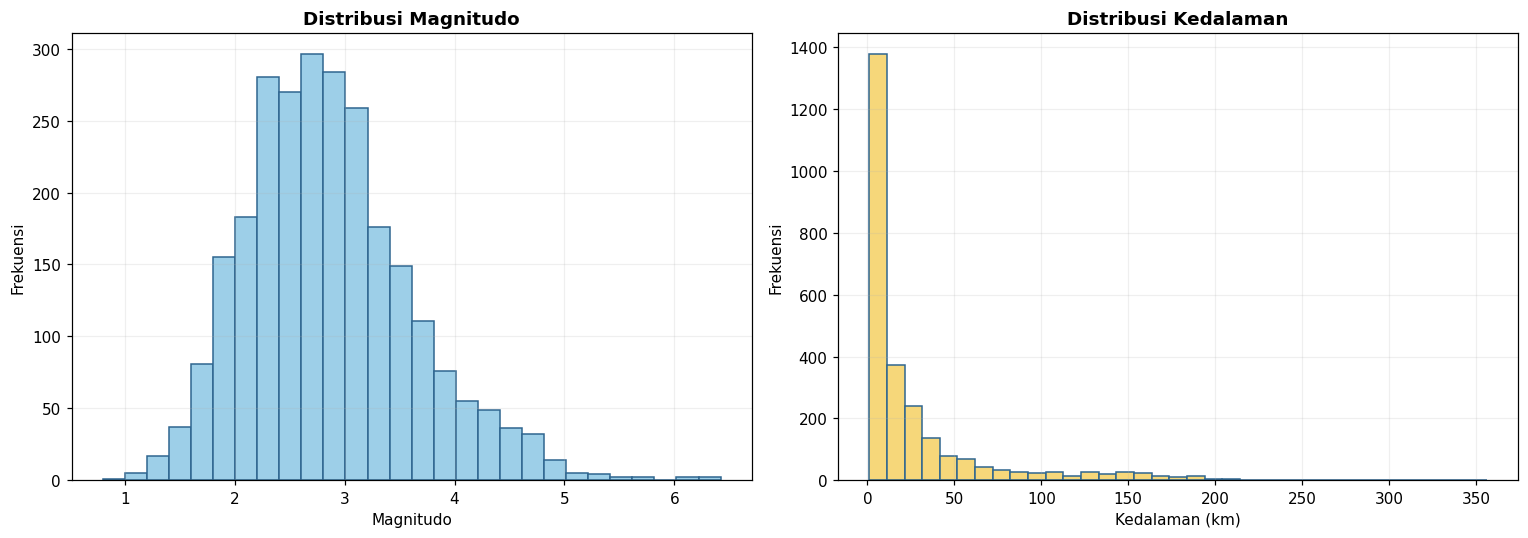

In [ ]:

# ============================================================
# 8. DISTRIBUSI DATA
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(
    df_analysis["Magnitude"],
    bins=28,
    color=SOFT_BLUE,
    edgecolor=BLUE_DARK
)
axes[0].set_title("Distribusi Magnitudo")
axes[0].set_xlabel("Magnitudo")
axes[0].set_ylabel("Frekuensi")
axes[0].grid(alpha=0.2)

axes[1].hist(
    df_analysis["Depth_km"],
    bins=35,
    color=SOFT_YELLOW,
    edgecolor=BLUE_DARK
)
axes[1].set_title("Distribusi Kedalaman")
axes[1].set_xlabel("Kedalaman (km)")
axes[1].set_ylabel("Frekuensi")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()



## 8. Statistika Inferensial

### Hipotesis Pearson
- **H₀:** korelasi linear populasi antara Magnitude dan Depth sama dengan 0.
- **H₁:** korelasi linear populasi antara Magnitude dan Depth tidak sama dengan 0.
- **Taraf signifikansi:** α = 0,05.

Pearson digunakan untuk mengukur hubungan linear. Spearman digunakan sebagai ukuran hubungan monotonik yang tidak hanya bergantung pada hubungan linear.


In [ ]:

# ============================================================
# 9A. KORELASI PEARSON + 95% CI
# ============================================================

alpha = 0.05

pearson_r, pearson_p = pearsonr(
    df_analysis["Magnitude"],
    df_analysis["Depth_km"]
)

# Interval kepercayaan Pearson menggunakan transformasi Fisher.
z = np.arctanh(pearson_r)
se = 1 / np.sqrt(len(df_analysis) - 3)
z_critical = 1.959964

ci_low = np.tanh(z - z_critical * se)
ci_high = np.tanh(z + z_critical * se)

print(f"Pearson r       = {pearson_r:.6f}")
print(f"p-value         = {pearson_p:.6e}")
print(f"95% CI Pearson  = [{ci_low:.3f}, {ci_high:.3f}]")
print(f"Alpha           = {alpha}")

if pearson_p < alpha:
    print("Keputusan       : Tolak H0.")
    print("Interpretasi     : terdapat bukti statistik adanya hubungan linear.")
else:
    print("Keputusan       : Gagal menolak H0.")

print(
    "\nKekuatan hubungan tetap dinilai dari nilai koefisien, "
    "bukan hanya dari p-value."
)


Pearson r       = 0.164066
p-value         = 4.809732e-17
95% CI Pearson  = [0.126, 0.201]
Alpha           = 0.05
Keputusan       : Tolak H0.
Interpretasi     : terdapat bukti statistik adanya hubungan linear.

Kekuatan hubungan tetap dinilai dari nilai koefisien, bukan hanya dari p-value.


In [ ]:

# ============================================================
# 9B. KORELASI SPEARMAN
# ============================================================

spearman_rho, spearman_p = spearmanr(
    df_analysis["Magnitude"],
    df_analysis["Depth_km"]
)

print(f"Spearman rho = {spearman_rho:.6f}")
print(f"p-value      = {spearman_p:.6e}")

if spearman_p < alpha:
    print("Keputusan    : Tolak H0 untuk uji hubungan monotonik.")
else:
    print("Keputusan    : Gagal menolak H0.")

print(
    f"Interpretasi : rho = {spearman_rho:.3f} menunjukkan "
    "hubungan monotonik positif yang lemah."
)


Spearman rho = 0.270964
p-value      = 1.053539e-44
Keputusan    : Tolak H0 untuk uji hubungan monotonik.
Interpretasi : rho = 0.271 menunjukkan hubungan monotonik positif yang lemah.


In [ ]:

# ============================================================
# 9C. REGRESI LINEAR SEDERHANA
# ============================================================

reg = linregress(
    df_analysis["Magnitude"],
    df_analysis["Depth_km"]
)

intercept = reg.intercept
slope = reg.slope
r2 = reg.rvalue ** 2

print(
    f"Persamaan regresi: Depth = {intercept:.3f} "
    f"+ {slope:.3f} * Magnitude"
)
print(f"R-squared         : {r2:.6f}")
print(
    f"Variasi Depth yang dijelaskan Magnitude: "
    f"{r2 * 100:.2f}%"
)
print(f"p-value slope     : {reg.pvalue:.6e}")

print(
    "\nInterpretasi: R² yang rendah menunjukkan bahwa Magnitude saja "
    "menjelaskan sebagian kecil variasi Depth pada data ini. "
    "Hasil ini tidak digunakan untuk menyatakan hubungan sebab-akibat."
)


Persamaan regresi: Depth = 2.735 + 8.768 * Magnitude
R-squared         : 0.026918
Variasi Depth yang dijelaskan Magnitude: 2.69%
p-value slope     : 4.809732e-17

Interpretasi: R² yang rendah menunjukkan bahwa Magnitude saja menjelaskan sebagian kecil variasi Depth pada data ini. Hasil ini tidak digunakan untuk menyatakan hubungan sebab-akibat.


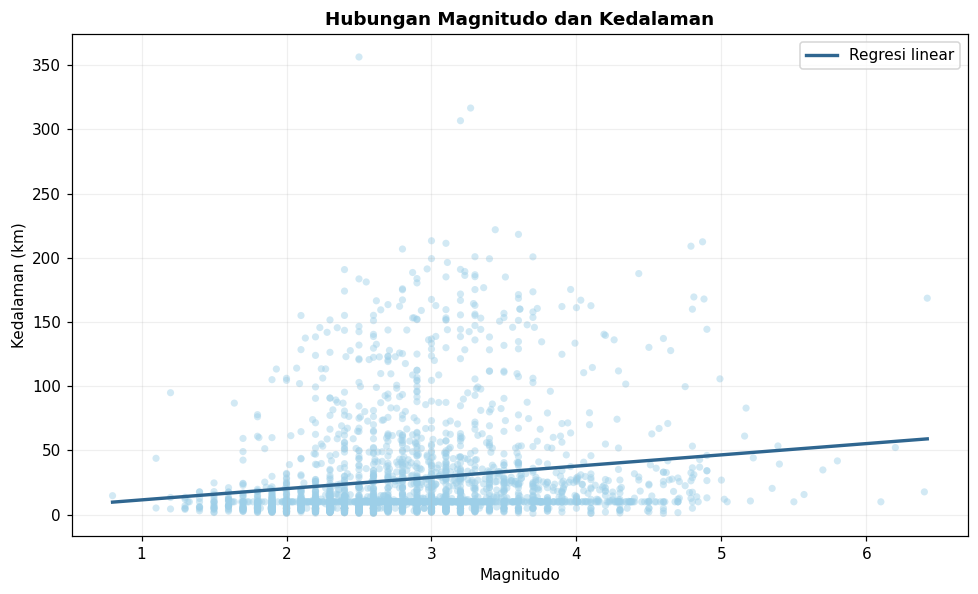

In [ ]:

# ============================================================
# 9D. SCATTER PLOT + GARIS REGRESI
# ============================================================

x_line = np.linspace(
    df_analysis["Magnitude"].min(),
    df_analysis["Magnitude"].max(),
    100
)
y_line = intercept + slope * x_line

plt.figure(figsize=(9, 5.5))
plt.scatter(
    df_analysis["Magnitude"],
    df_analysis["Depth_km"],
    s=22,
    alpha=0.45,
    color=SOFT_BLUE,
    edgecolors="none"
)
plt.plot(
    x_line,
    y_line,
    color=BLUE_DARK,
    linewidth=2.2,
    label="Regresi linear"
)

plt.title("Hubungan Magnitudo dan Kedalaman")
plt.xlabel("Magnitudo")
plt.ylabel("Kedalaman (km)")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()



### Pemeriksaan asumsi dan keterbatasan regresi

- Hubungan linear diperiksa secara visual melalui scatter plot.
- Residual diperiksa melalui residual-vs-fitted dan histogram residual.
- Pencilan tidak dihapus otomatis.
- Independensi observasi perlu dipertimbangkan karena kejadian gempa dapat memiliki keterkaitan temporal atau berada dalam rangkaian kejadian tertentu.
- Karena hubungan Pearson relatif lemah dan R² kecil, regresi sederhana ini lebih tepat digunakan untuk **menggambarkan hubungan pada data**, bukan sebagai model prediksi yang andal.


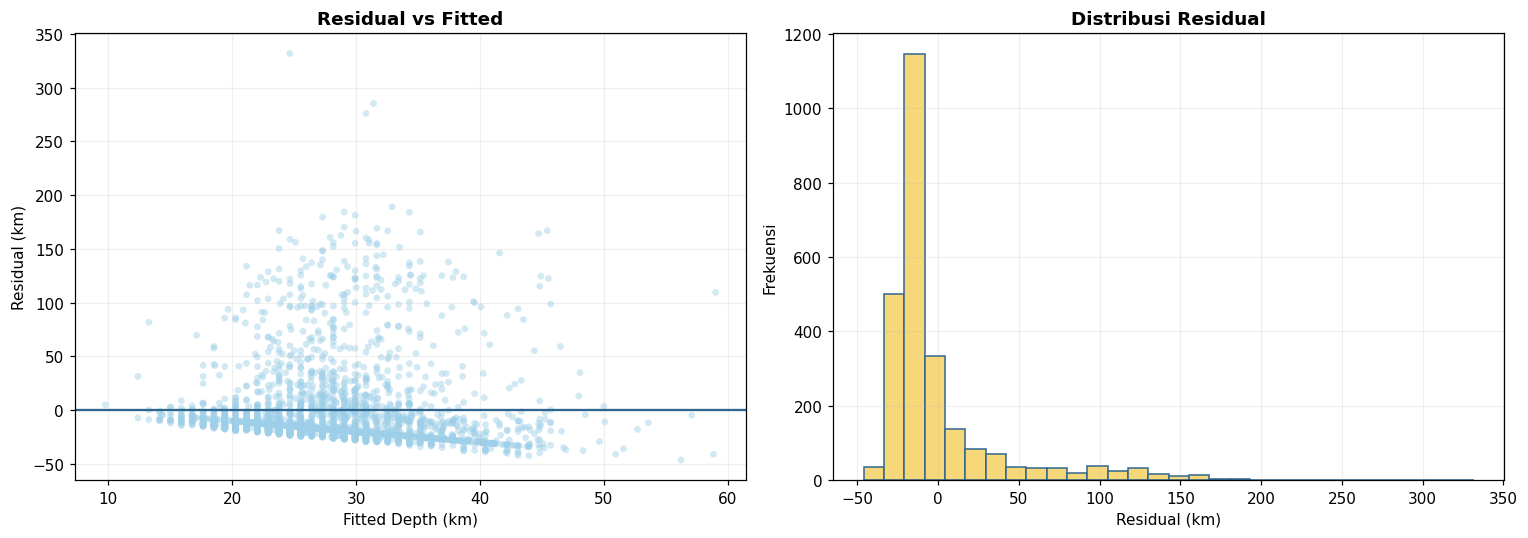

In [ ]:

# ============================================================
# 9E. DIAGNOSTIK RESIDUAL REGRESI
# ============================================================

fitted = intercept + slope * df_analysis["Magnitude"]
residuals = df_analysis["Depth_km"] - fitted

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    fitted,
    residuals,
    s=20,
    alpha=0.45,
    color=SOFT_BLUE,
    edgecolors="none"
)
axes[0].axhline(0, color=BLUE_DARK, linewidth=1.5)
axes[0].set_title("Residual vs Fitted")
axes[0].set_xlabel("Fitted Depth (km)")
axes[0].set_ylabel("Residual (km)")
axes[0].grid(alpha=0.2)

axes[1].hist(
    residuals,
    bins=30,
    color=SOFT_YELLOW,
    edgecolor=BLUE_DARK
)
axes[1].set_title("Distribusi Residual")
axes[1].set_xlabel("Residual (km)")
axes[1].set_ylabel("Frekuensi")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()



## 9. Standardisasi Variabel

Magnitude dan Depth memiliki skala penyebaran yang berbeda. Sebelum K-Means, kedua variabel distandardisasi menggunakan `StandardScaler` agar kontribusi variabel tidak didominasi oleh perbedaan skala pengukuran.


In [ ]:

# ============================================================
# 10. STANDARDISASI
# ============================================================

X = df_analysis[["Magnitude", "Depth_km"]].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Mean setelah standardisasi:", X_scaled.mean(axis=0).round(6))
print("Std setelah standardisasi :", X_scaled.std(axis=0).round(6))


Mean setelah standardisasi: [ 0. -0.]
Std setelah standardisasi : [1. 1.]



## 10. Evaluasi jumlah cluster

Elbow Method dan Silhouette Score dihitung untuk kandidat **K=2 sampai K=7**.

**Catatan penting:** Silhouette digunakan sebagai ukuran kekompakan dan pemisahan cluster, **bukan akurasi**.

Hasil evaluasi digunakan sebagai informasi untuk menentukan konfigurasi clustering. Pada project ini, **K=3 dipilih sebagai pengelompokan eksploratif**, bukan karena memiliki silhouette tertinggi.


In [ ]:

# ============================================================
# 11. ELBOW METHOD + SILHOUETTE SCORE
# ============================================================

eval_rows = []

for k in range(2, 8):
    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    labels_k = km.fit_predict(X_scaled)

    eval_rows.append({
        "K": k,
        "Inertia": km.inertia_,
        "Silhouette": silhouette_score(X_scaled, labels_k)
    })

eval_df = pd.DataFrame(eval_rows)

display(eval_df.round(6))

best_k = int(
    eval_df.loc[
        eval_df["Silhouette"].idxmax(),
        "K"
    ]
)

silhouette_k3 = float(
    eval_df.loc[
        eval_df["K"] == 3,
        "Silhouette"
    ].iloc[0]
)

print(f"Silhouette tertinggi : K={best_k}")
print(f"Silhouette K=3       : {silhouette_k3:.6f}")

print(
    "\nKeputusan project: K=3 digunakan sebagai pengelompokan "
    "eksploratif untuk memperoleh tiga kelompok karakteristik."
)


,K,Inertia,Silhouette
0,2,3174.112138,0.589256
1,3,1692.863630,0.474124
2,4,1243.509351,0.424569
3,5,989.234376,0.441789
4,6,831.723891,0.401869
5,7,727.960017,0.406631


Silhouette tertinggi : K=2
Silhouette K=3       : 0.474124

Keputusan project: K=3 digunakan sebagai pengelompokan eksploratif untuk memperoleh tiga kelompok karakteristik.


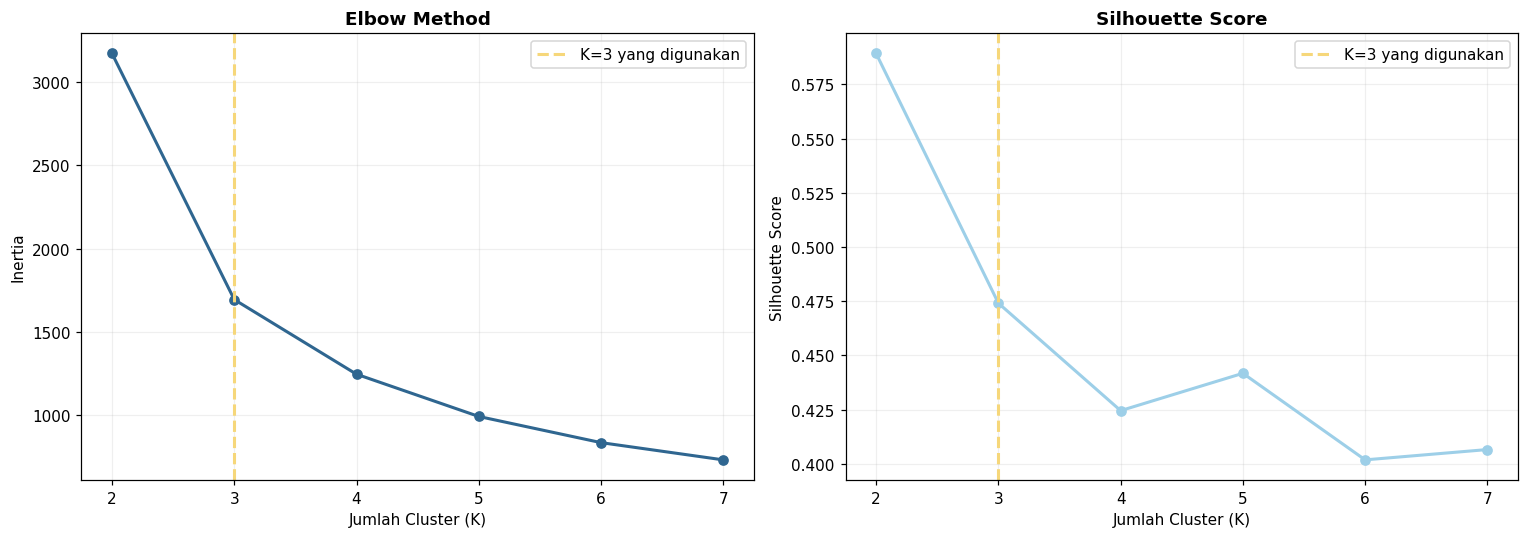

In [ ]:

# ============================================================
# 12. VISUALISASI EVALUASI K
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    eval_df["K"],
    eval_df["Inertia"],
    marker="o",
    color=BLUE_DARK,
    linewidth=2
)
axes[0].axvline(
    3,
    linestyle="--",
    color=SOFT_YELLOW,
    linewidth=2,
    label="K=3 yang digunakan"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Jumlah Cluster (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.2)
axes[0].legend()

axes[1].plot(
    eval_df["K"],
    eval_df["Silhouette"],
    marker="o",
    color=SOFT_BLUE,
    linewidth=2
)
axes[1].axvline(
    3,
    linestyle="--",
    color=SOFT_YELLOW,
    linewidth=2,
    label="K=3 yang digunakan"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Jumlah Cluster (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.2)
axes[1].legend()

plt.tight_layout()
plt.show()



## 11. K-Means Final — 3 Cluster

Label cluster pada K-Means bersifat arbitrer. Karena itu, label berikut ditetapkan **setelah melihat centroid pada skala asli**, bukan berdasarkan nomor cluster mentah dari algoritma.

Label karakteristik yang digunakan:

1. **Magnitudo Relatif Rendah & Dangkal**
2. **Magnitudo Relatif Sedang & Dalam**
3. **Magnitudo Relatif Tinggi & Dangkal**

Kata **“relatif”** berarti perbandingan karakteristik antarcluster dalam dataset penelitian, bukan kategori resmi kegempaan dan bukan penilaian risiko bencana.


In [ ]:

# ============================================================
# 13. K-MEANS FINAL — 3 CLUSTER
# ============================================================

K_FINAL = 3

kmeans = KMeans(
    n_clusters=K_FINAL,
    random_state=42,
    n_init=20
)

raw_labels = kmeans.fit_predict(X_scaled) + 1

# Centroid dikembalikan ke skala asli.
raw_centroids = scaler.inverse_transform(kmeans.cluster_centers_)

centers = pd.DataFrame(
    raw_centroids,
    columns=["Magnitude_Centroid", "Depth_Centroid_km"]
)
centers["RawCluster"] = np.arange(1, K_FINAL + 1)

display(centers.round(3))

# ------------------------------------------------------------
# Remapping berdasarkan karakteristik centroid
# ------------------------------------------------------------
deep_raw = int(
    centers.loc[
        centers["Depth_Centroid_km"].idxmax(),
        "RawCluster"
    ]
)

remaining = centers[
    centers["RawCluster"] != deep_raw
].sort_values("Magnitude_Centroid")

lowmag_raw = int(remaining.iloc[0]["RawCluster"])
highmag_raw = int(remaining.iloc[-1]["RawCluster"])

remap = {
    lowmag_raw: 1,
    deep_raw: 2,
    highmag_raw: 3
}

print("Pemetaan RawCluster → Cluster analisis:", remap)

df_analysis["Cluster"] = (
    pd.Series(raw_labels, index=df_analysis.index).map(remap)
)

label_map = {
    1: "Magnitudo Relatif Rendah & Dangkal",
    2: "Magnitudo Relatif Sedang & Dalam",
    3: "Magnitudo Relatif Tinggi & Dangkal"
}

explanation_map = {
    1: (
        "Cluster dengan magnitudo rata-rata relatif rendah dan "
        "kedalaman rata-rata relatif dangkal dibandingkan cluster lain."
    ),
    2: (
        "Cluster dengan kedalaman rata-rata paling besar dan "
        "magnitudo rata-rata berada pada tingkat menengah dibandingkan cluster lain."
    ),
    3: (
        "Cluster dengan magnitudo rata-rata relatif paling tinggi "
        "dan kedalaman rata-rata relatif dangkal."
    )
}

df_analysis["Label"] = df_analysis["Cluster"].map(label_map)

# Centroid setelah remapping
centroid_display = (
    df_analysis.groupby("Cluster")
    .agg(
        Magnitude_Centroid=("Magnitude", "mean"),
        Depth_Centroid_km=("Depth_km", "mean")
    )
    .reset_index()
)

centroid_display["Label"] = centroid_display["Cluster"].map(label_map)

display(centroid_display.round(3))


,Magnitude_Centroid,Depth_Centroid_km,RawCluster
0,2.414,15.123,1
1,3.651,20.056,2
2,3.113,136.157,3


Pemetaan RawCluster → Cluster analisis: {1: 1, 3: 2, 2: 3}


,Cluster,Magnitude_Centroid,Depth_Centroid_km,Label
0,1,2.414,15.123,Magnitudo Relatif Rendah & Dangkal
1,2,3.113,136.157,Magnitudo Relatif Sedang & Dalam
2,3,3.651,20.056,Magnitudo Relatif Tinggi & Dangkal


In [ ]:

# ============================================================
# 14. RINGKASAN SETIAP CLUSTER
# ============================================================

cluster_summary = (
    df_analysis
    .groupby(["Cluster", "Label"])
    .agg(
        Jumlah=("Magnitude", "size"),
        Rata_Magnitude=("Magnitude", "mean"),
        Median_Magnitude=("Magnitude", "median"),
        Std_Magnitude=("Magnitude", "std"),
        Min_Magnitude=("Magnitude", "min"),
        Max_Magnitude=("Magnitude", "max"),
        Rata_Depth_km=("Depth_km", "mean"),
        Median_Depth_km=("Depth_km", "median"),
        Std_Depth_km=("Depth_km", "std"),
        Min_Depth_km=("Depth_km", "min"),
        Max_Depth_km=("Depth_km", "max")
    )
    .reset_index()
)

cluster_summary["Persentase"] = (
    cluster_summary["Jumlah"] / len(df_analysis) * 100
)

cluster_summary["Penjelasan"] = (
    cluster_summary["Cluster"].map(explanation_map)
)

cluster_summary = cluster_summary.sort_values("Cluster").reset_index(drop=True)

display(
    cluster_summary[
        [
            "Cluster", "Label", "Jumlah", "Persentase",
            "Rata_Magnitude", "Median_Magnitude",
            "Rata_Depth_km", "Median_Depth_km",
            "Min_Depth_km", "Max_Depth_km",
            "Penjelasan"
        ]
    ].round(3)
)

print("\nINTERPRETASI CLUSTER")
for _, row in cluster_summary.iterrows():
    print(f"\nC{int(row['Cluster'])} — {row['Label']}")
    print(f"- Jumlah       : {int(row['Jumlah']):,} ({row['Persentase']:.2f}%)")
    print(f"- Mean Magnitude: {row['Rata_Magnitude']:.3f}")
    print(f"- Mean Depth    : {row['Rata_Depth_km']:.3f} km")
    print(f"- Penjelasan    : {row['Penjelasan']}")


,Cluster,Label,Jumlah,Persentase,Rata_Magnitude,Median_Magnitude,Rata_Depth_km,Median_Depth_km,Min_Depth_km,Max_Depth_km,Penjelasan
0,1,Magnitudo Relatif Rendah & Dangkal,1493,57.801,2.414,2.49,15.123,10.00,1.00,94.97,Cluster dengan magnitudo rata-rata relatif ren...
1,2,Magnitudo Relatif Sedang & Dalam,241,9.330,3.113,3.00,136.157,132.69,73.22,356.43,Cluster dengan kedalaman rata-rata paling besa...
2,3,Magnitudo Relatif Tinggi & Dangkal,849,32.869,3.651,3.50,20.056,11.79,1.00,83.01,Cluster dengan magnitudo rata-rata relatif pal...



INTERPRETASI CLUSTER

C1 — Magnitudo Relatif Rendah & Dangkal
- Jumlah       : 1,493 (57.80%)
- Mean Magnitude: 2.414
- Mean Depth    : 15.123 km
- Penjelasan    : Cluster dengan magnitudo rata-rata relatif rendah dan kedalaman rata-rata relatif dangkal dibandingkan cluster lain.

C2 — Magnitudo Relatif Sedang & Dalam
- Jumlah       : 241 (9.33%)
- Mean Magnitude: 3.113
- Mean Depth    : 136.157 km
- Penjelasan    : Cluster dengan kedalaman rata-rata paling besar dan magnitudo rata-rata berada pada tingkat menengah dibandingkan cluster lain.

C3 — Magnitudo Relatif Tinggi & Dangkal
- Jumlah       : 849 (32.87%)
- Mean Magnitude: 3.651
- Mean Depth    : 20.056 km
- Penjelasan    : Cluster dengan magnitudo rata-rata relatif paling tinggi dan kedalaman rata-rata relatif dangkal.


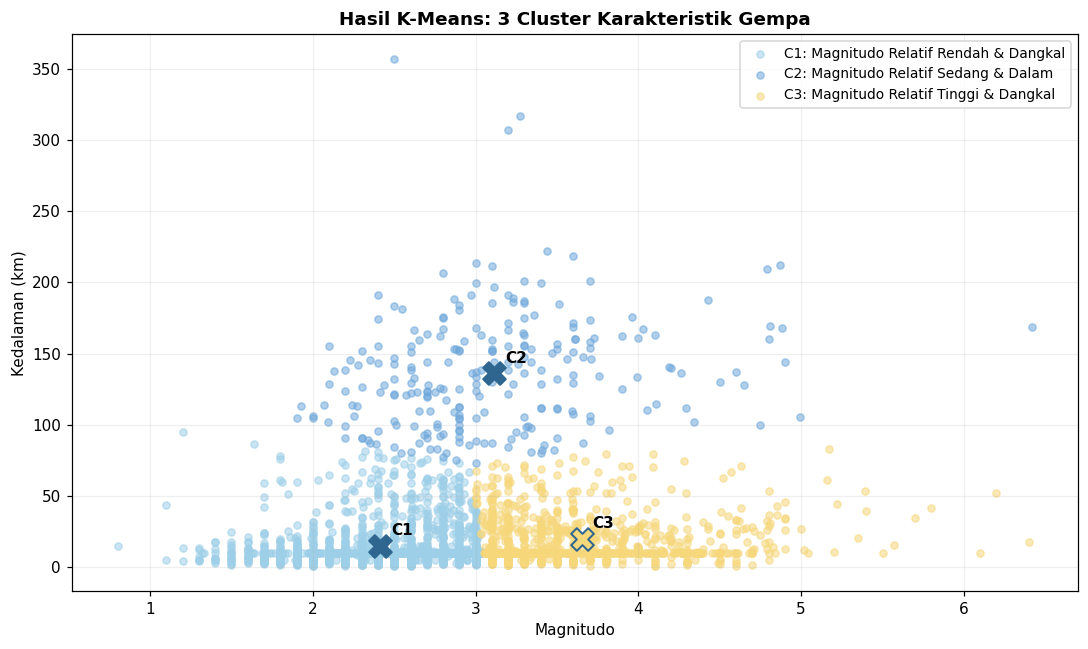

In [ ]:

# ============================================================
# 15. VISUALISASI HASIL K-MEANS
# ============================================================

cluster_colors = {
    1: SOFT_BLUE,
    2: "#6FA8DC",
    3: SOFT_YELLOW
}

plt.figure(figsize=(10, 6))

for c in [1, 2, 3]:
    sub = df_analysis[df_analysis["Cluster"] == c]

    plt.scatter(
        sub["Magnitude"],
        sub["Depth_km"],
        s=22,
        alpha=0.55,
        color=cluster_colors[c],
        label=f"C{c}: {label_map[c]}"
    )

for _, row in centroid_display.iterrows():
    c = int(row["Cluster"])

    plt.scatter(
        row["Magnitude_Centroid"],
        row["Depth_Centroid_km"],
        marker="X",
        s=220,
        color=SOFT_YELLOW if c == 3 else BLUE_DARK,
        edgecolor=BLUE_DARK,
        linewidth=1.3,
        zorder=5
    )

    plt.annotate(
        f"C{c}",
        (row["Magnitude_Centroid"], row["Depth_Centroid_km"]),
        xytext=(7, 7),
        textcoords="offset points",
        fontweight="bold"
    )

plt.title("Hasil K-Means: 3 Cluster Karakteristik Gempa")
plt.xlabel("Magnitudo")
plt.ylabel("Kedalaman (km)")
plt.grid(alpha=0.2)
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()



## 12. Kesimpulan Analisis Sementara

Bagian ini merangkum **hasil analisis pada tahap project saat ini**. Kesimpulan tidak menyebut hasil clustering sebagai risiko bencana dan tidak menyatakan K=3 sebagai konfigurasi optimal berdasarkan silhouette.


In [ ]:

# ============================================================
# 16. KESIMPULAN ANALISIS
# ============================================================

print("=" * 70)
print("KESIMPULAN ANALISIS")
print("=" * 70)

print(
    f"1. Dataset final yang dianalisis berjumlah {len(df_analysis):,} observasi "
    "setelah deduplikasi dan penyaringan cakupan geografis."
)

print(
    f"2. Rata-rata Magnitude = {mean_mag:.3f}, "
    f"sedangkan rata-rata Depth = {mean_depth:.3f} km."
)

print(
    f"3. Pearson r = {pearson_r:.3f} dan Spearman rho = {spearman_rho:.3f}. "
    "Keduanya menunjukkan hubungan positif yang lemah."
)

print(
    f"4. R² regresi = {r2:.4f}, sehingga Magnitude menjelaskan sekitar "
    f"{r2*100:.2f}% variasi Depth dalam model linear sederhana."
)

print(
    f"5. Silhouette tertinggi pada kandidat K=2–7 adalah K={best_k} "
    f"({eval_df.loc[eval_df['K']==best_k, 'Silhouette'].iloc[0]:.4f})."
)

print(
    f"6. K=3 digunakan sebagai pengelompokan eksploratif untuk memperoleh "
    f"tiga kelompok karakteristik. Silhouette K=3 = {silhouette_k3:.4f}."
)

for _, row in cluster_summary.iterrows():
    print(
        f"7. C{int(row['Cluster'])} ({row['Label']}) berjumlah "
        f"{int(row['Jumlah']):,} observasi atau {row['Persentase']:.2f}%."
    )

print(
    "\nBatasan: hasil ini menggambarkan catatan gempa pada periode dan "
    "cakupan dataset yang dianalisis. Label cluster merupakan karakteristik "
    "relatif berdasarkan Magnitude dan Depth, bukan klasifikasi risiko bencana."
)


KESIMPULAN ANALISIS
1. Dataset final yang dianalisis berjumlah 2,583 observasi setelah deduplikasi dan penyaringan cakupan geografis.
2. Rata-rata Magnitude = 2.886, sedangkan rata-rata Depth = 28.037 km.
3. Pearson r = 0.164 dan Spearman rho = 0.271. Keduanya menunjukkan hubungan positif yang lemah.
4. R² regresi = 0.0269, sehingga Magnitude menjelaskan sekitar 2.69% variasi Depth dalam model linear sederhana.
5. Silhouette tertinggi pada kandidat K=2–7 adalah K=2 (0.5893).
6. K=3 digunakan sebagai pengelompokan eksploratif untuk memperoleh tiga kelompok karakteristik. Silhouette K=3 = 0.4741.
7. C1 (Magnitudo Relatif Rendah & Dangkal) berjumlah 1,493 observasi atau 57.80%.
7. C2 (Magnitudo Relatif Sedang & Dalam) berjumlah 241 observasi atau 9.33%.
7. C3 (Magnitudo Relatif Tinggi & Dangkal) berjumlah 849 observasi atau 32.87%.

Batasan: hasil ini menggambarkan catatan gempa pada periode dan cakupan dataset yang dianalisis. Label cluster merupakan karakteristik relatif berdasarkan Mag


# 13. Dashboard Analisis Gempa Sumatera

Dashboard berikut merangkum hasil utama project pada satu tampilan:
- jumlah observasi;
- mean Magnitude;
- mean Depth;
- distribusi Magnitude;
- distribusi Depth;
- hubungan Magnitude–Depth;
- ukuran tiga cluster;
- ringkasan karakteristik cluster;
- Silhouette K=3.

Dashboard **tidak menggunakan label risiko rendah/sedang/tinggi**. Label yang ditampilkan adalah label karakteristik hasil clustering.


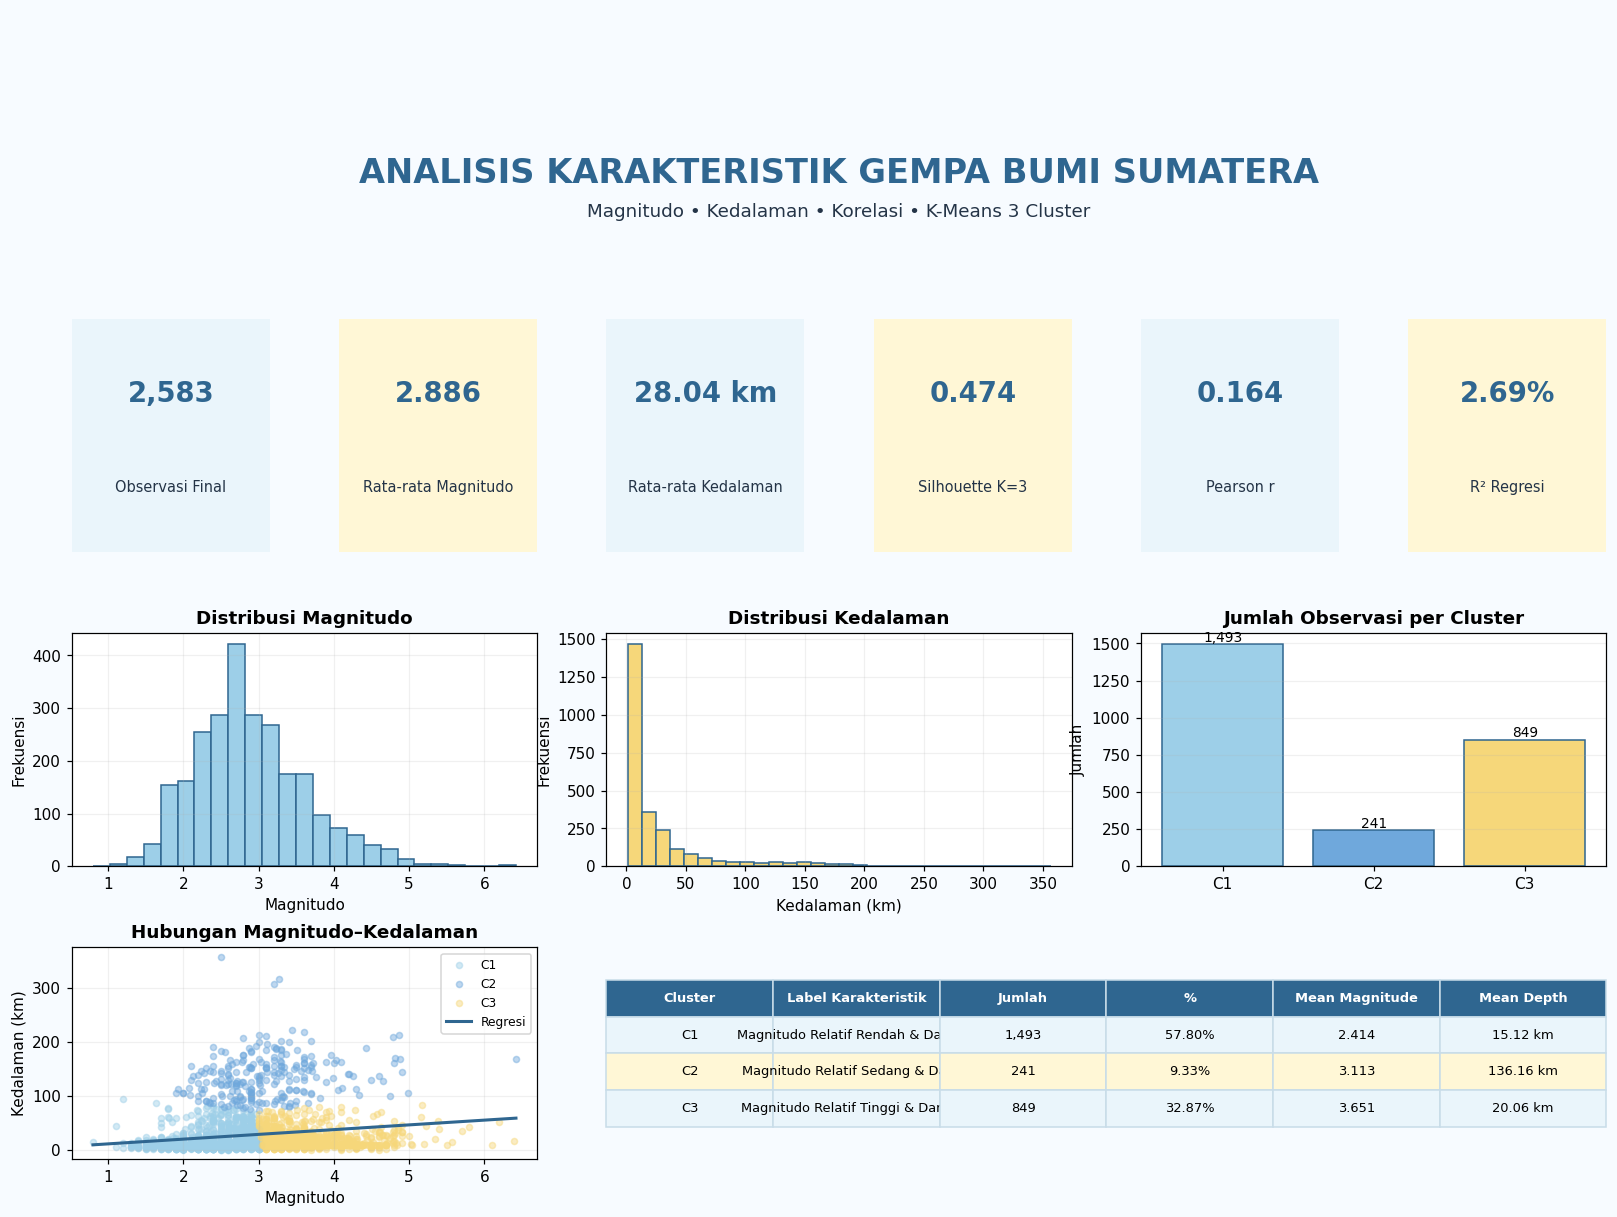

In [ ]:

# ============================================================
# 17. DASHBOARD PROFESIONAL — SOFT BLUE & SOFT YELLOW
# ============================================================

import matplotlib.patches as patches

fig = plt.figure(figsize=(18, 12), facecolor="#F7FBFF")

# Grid dashboard 4 baris x 6 kolom
gs = fig.add_gridspec(
    4, 6,
    height_ratios=[0.9, 2.2, 2.2, 2.0],
    hspace=0.42,
    wspace=0.35
)

# ------------------------------------------------------------
# Header
# ------------------------------------------------------------
ax_header = fig.add_subplot(gs[0, :])
ax_header.axis("off")

ax_header.text(
    0.5, 0.68,
    "ANALISIS KARAKTERISTIK GEMPA BUMI SUMATERA",
    ha="center",
    va="center",
    fontsize=22,
    fontweight="bold",
    color=BLUE_DARK
)

ax_header.text(
    0.5, 0.28,
    "Magnitudo • Kedalaman • Korelasi • K-Means 3 Cluster",
    ha="center",
    va="center",
    fontsize=12,
    color=TEXT_DARK
)

# ------------------------------------------------------------
# KPI cards
# ------------------------------------------------------------
kpi_data = [
    ("Observasi Final", f"{len(df_analysis):,}", BLUE_LIGHT, BLUE_DARK),
    ("Rata-rata Magnitudo", f"{mean_mag:.3f}", YELLOW_LIGHT, BLUE_DARK),
    ("Rata-rata Kedalaman", f"{mean_depth:.2f} km", BLUE_LIGHT, BLUE_DARK),
    ("Silhouette K=3", f"{silhouette_k3:.3f}", YELLOW_LIGHT, BLUE_DARK),
    ("Pearson r", f"{pearson_r:.3f}", BLUE_LIGHT, BLUE_DARK),
    ("R² Regresi", f"{r2*100:.2f}%", YELLOW_LIGHT, BLUE_DARK),
]

for i, (title, value, face, text_color) in enumerate(kpi_data):
    ax = fig.add_subplot(gs[1, i])
    ax.set_facecolor(face)
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.text(
        0.5, 0.68, value,
        ha="center",
        va="center",
        fontsize=18,
        fontweight="bold",
        color=text_color
    )
    ax.text(
        0.5, 0.28, title,
        ha="center",
        va="center",
        fontsize=9.5,
        color=TEXT_DARK
    )

# ------------------------------------------------------------
# Distribusi Magnitude
# ------------------------------------------------------------
ax1 = fig.add_subplot(gs[2, 0:2])
ax1.hist(
    df_analysis["Magnitude"],
    bins=25,
    color=SOFT_BLUE,
    edgecolor=BLUE_DARK
)
ax1.set_title("Distribusi Magnitudo", fontsize=12)
ax1.set_xlabel("Magnitudo")
ax1.set_ylabel("Frekuensi")
ax1.grid(alpha=0.18)

# ------------------------------------------------------------
# Distribusi Depth
# ------------------------------------------------------------
ax2 = fig.add_subplot(gs[2, 2:4])
ax2.hist(
    df_analysis["Depth_km"],
    bins=30,
    color=SOFT_YELLOW,
    edgecolor=BLUE_DARK
)
ax2.set_title("Distribusi Kedalaman", fontsize=12)
ax2.set_xlabel("Kedalaman (km)")
ax2.set_ylabel("Frekuensi")
ax2.grid(alpha=0.18)

# ------------------------------------------------------------
# Jumlah Cluster
# ------------------------------------------------------------
ax3 = fig.add_subplot(gs[2, 4:6])
cluster_counts = cluster_summary["Jumlah"]
bars = ax3.bar(
    [f"C{i}" for i in cluster_summary["Cluster"]],
    cluster_counts,
    color=[cluster_colors[int(c)] for c in cluster_summary["Cluster"]],
    edgecolor=BLUE_DARK
)
ax3.set_title("Jumlah Observasi per Cluster", fontsize=12)
ax3.set_ylabel("Jumlah")
ax3.grid(axis="y", alpha=0.18)

for bar, count in zip(bars, cluster_counts):
    ax3.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{int(count):,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# ------------------------------------------------------------
# Scatter hubungan Magnitude-Depth
# ------------------------------------------------------------
ax4 = fig.add_subplot(gs[3, 0:2])

for c in [1, 2, 3]:
    sub = df_analysis[df_analysis["Cluster"] == c]
    ax4.scatter(
        sub["Magnitude"],
        sub["Depth_km"],
        s=16,
        alpha=0.45,
        color=cluster_colors[c],
        label=f"C{c}"
    )

ax4.plot(
    x_line,
    y_line,
    color=BLUE_DARK,
    linewidth=2,
    label="Regresi"
)

ax4.set_title("Hubungan Magnitudo–Kedalaman", fontsize=12)
ax4.set_xlabel("Magnitudo")
ax4.set_ylabel("Kedalaman (km)")
ax4.grid(alpha=0.18)
ax4.legend(fontsize=8)

# ------------------------------------------------------------
# Ringkasan cluster
# ------------------------------------------------------------
ax5 = fig.add_subplot(gs[3, 2:6])
ax5.axis("off")

table_data = []

for _, row in cluster_summary.iterrows():
    table_data.append([
        f"C{int(row['Cluster'])}",
        row["Label"],
        f"{int(row['Jumlah']):,}",
        f"{row['Persentase']:.2f}%",
        f"{row['Rata_Magnitude']:.3f}",
        f"{row['Rata_Depth_km']:.2f} km"
    ])

table = ax5.table(
    cellText=table_data,
    colLabels=[
        "Cluster", "Label Karakteristik", "Jumlah", "%",
        "Mean Magnitude", "Mean Depth"
    ],
    cellLoc="center",
    colLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(8.5)
table.scale(1, 2.0)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#C8DCE8")

    if row == 0:
        cell.set_facecolor(BLUE_DARK)
        cell.set_text_props(color="white", weight="bold")
    else:
        cell.set_facecolor(
            BLUE_LIGHT if row % 2 == 1 else YELLOW_LIGHT
        )

plt.suptitle(
    "Dashboard Analisis Gempa Sumatera",
    fontsize=1,
    color="#F7FBFF"
)

plt.show()



### Catatan dashboard

Dashboard digunakan sebagai **ringkasan hasil analisis**, bukan sebagai sistem penilaian risiko bencana. Cluster diberi label berdasarkan karakteristik relatif Magnitude dan Depth yang diperoleh dari centroid dan ringkasan masing-masing cluster.


In [ ]:

# ============================================================
# 15. EXPORT HASIL ANALISIS
# ============================================================

import os

output_excel = "hasil_analisis_gempa_sumatera_FINAL_K3.xlsx"

# Statistik inferensial ringkas
statistical_summary = pd.DataFrame({
    "Ukuran": [
        "Jumlah observasi final",
        "Pearson r",
        "Pearson p-value",
        "Pearson CI lower 95%",
        "Pearson CI upper 95%",
        "Spearman rho",
        "Spearman p-value",
        "Intercept regresi",
        "Slope regresi",
        "R-squared",
        "Silhouette K=3",
        "K terbaik berdasarkan silhouette"
    ],
    "Nilai": [
        len(df_analysis),
        pearson_r,
        pearson_p,
        ci_low,
        ci_high,
        spearman_rho,
        spearman_p,
        intercept,
        slope,
        r2,
        silhouette_k3,
        best_k
    ]
})

with pd.ExcelWriter(output_excel, engine="openpyxl") as writer:
    df_analysis.to_excel(
        writer,
        sheet_name="Data_Final_Cluster",
        index=False
    )

    cluster_summary.to_excel(
        writer,
        sheet_name="Ringkasan_Cluster",
        index=False
    )

    centroid_display.to_excel(
        writer,
        sheet_name="Centroid_Cluster",
        index=False
    )

    eval_df.to_excel(
        writer,
        sheet_name="Evaluasi_K",
        index=False
    )

    desc.to_excel(
        writer,
        sheet_name="Statistik_Deskriptif"
    )

    statistical_summary.to_excel(
        writer,
        sheet_name="Statistik_Inferensial",
        index=False
    )

    cleaning_summary.to_excel(
        writer,
        sheet_name="Pembersihan_Data",
        index=False
    )

print("=" * 70)
print("EXPORT BERHASIL")
print("=" * 70)
print(f"File hasil: {output_excel}")
print(f"Ukuran file: {os.path.getsize(output_excel) / 1024:.1f} KB")
print("Sheet yang dibuat:")
print("- Data_Final_Cluster")
print("- Ringkasan_Cluster")
print("- Centroid_Cluster")
print("- Evaluasi_K")
print("- Statistik_Deskriptif")
print("- Statistik_Inferensial")
print("- Pembersihan_Data")


EXPORT BERHASIL
File hasil: hasil_analisis_gempa_sumatera_FINAL_K3.xlsx
Ukuran file: 138.0 KB
Sheet yang dibuat:
- Data_Final_Cluster
- Ringkasan_Cluster
- Centroid_Cluster
- Evaluasi_K
- Statistik_Deskriptif
- Statistik_Inferensial
- Pembersihan_Data
